# Statistical modelling

The outcome is reported KSI (Fatal or Serious) versus Slight. This notebook fits a multivariable logistic regression on a stratified training set, reports odds ratios with 95% confidence intervals, checks category sizes and VIFs, and evaluates test-set AUC against a constant-score baseline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "collisions_clean.csv")
df["year"] = df["year"].astype(int)
df["ksi"] = df["ksi"].astype(int)

model_factors = [
    "speed_limit_band",
    "light",
    "weather",
    "road_surface",
    "urban_rural",
    "road_type",
    "junction_detail",
    "day_of_week",
    "time_of_day",
    "vehicle_count_band",
    "year",
]

invalid_speed_limit = df["speed_limit_band"].eq("Unknown / missing")
model_df = df.loc[~invalid_speed_limit].copy()
print(f"Excluded from model for unknown speed limit: {invalid_speed_limit.sum():,}")

train, test = train_test_split(
    model_df,
    test_size=0.20,
    random_state=42,
    stratify=model_df["ksi"],
)
print(f"Training rows: {len(train):,}; test rows: {len(test):,}")
print(f"Training KSI rate: {train['ksi'].mean():.2%}")

sample_rows = []
for factor in model_factors:
    counts = train[factor].value_counts(dropna=False)
    for category, count in counts.items():
        sample_rows.append(
            {"factor": factor, "category": category, "training_collisions": count}
        )
sample_sizes = pd.DataFrame(sample_rows)
print("Categories with fewer than 100 training collisions:")
display(sample_sizes[sample_sizes["training_collisions"] < 100].sort_values("training_collisions"))

Excluded from model for unknown speed limit: 3
Training rows: 245,365; test rows: 61,342
Training KSI rate: 25.00%
Categories with fewer than 100 training collisions:


,factor,category,training_collisions
22,urban_rural,Unknown / missing,5
21,urban_rural,Unallocated,8
9,light,Unknown / missing,20


## Logistic regression

Categorical predictors use explicit reference groups so each odds ratio compares a named category with a clear baseline. The model adjusts for the listed conditions simultaneously; its estimates are associations, not causal effects.

In [2]:
formula = """
ksi ~ C(speed_limit_band, Treatment(reference='20-30 mph'))
    + C(light, Treatment(reference='Daylight'))
    + C(weather, Treatment(reference='Fine'))
    + C(road_surface, Treatment(reference='Dry'))
    + C(urban_rural, Treatment(reference='Urban'))
    + C(road_type, Treatment(reference='Single carriageway'))
    + C(junction_detail, Treatment(reference='Not at or near a junction'))
    + C(day_of_week, Treatment(reference='Monday'))
    + C(time_of_day, Treatment(reference='Daytime'))
    + C(vehicle_count_band, Treatment(reference='1'))
    + C(year, Treatment(reference=2023))
"""

model = smf.logit(formula=formula, data=train).fit(disp=False, maxiter=100)

confidence_intervals = model.conf_int()
odds_ratios = pd.DataFrame(
    {
        "term": model.params.index,
        "odds_ratio": np.exp(model.params),
        "ci_lower": np.exp(confidence_intervals[0]),
        "ci_upper": np.exp(confidence_intervals[1]),
        "p_value": model.pvalues,
    }
).reset_index(drop=True)
odds_ratios = odds_ratios[odds_ratios["term"] != "Intercept"].copy()
odds_ratios = odds_ratios.sort_values("odds_ratio", ascending=False)

print(model.summary())
print("\nOdds ratios with 95% confidence intervals")
display(odds_ratios.round(3))

model_table_path = PROJECT_ROOT / "data" / "processed" / "logistic_odds_ratios.csv"
odds_ratios.to_csv(model_table_path, index=False)
print(f"Saved odds-ratio table to {model_table_path.relative_to(PROJECT_ROOT)}")

                           Logit Regression Results                           
Dep. Variable:                    ksi   No. Observations:               245365
Model:                          Logit   Df Residuals:                   245322
Method:                           MLE   Df Model:                           42
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.03060
Time:                        22:28:32   Log-Likelihood:            -1.3375e+05
converged:                       True   LL-Null:                   -1.3797e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                                                                coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Intercept           

,term,odds_ratio,ci_lower,ci_upper,p_value
18,"C(urban_rural, Treatment(reference='Urban'))[T...",2.426,0.399,14.754,0.336
17,"C(urban_rural, Treatment(reference='Urban'))[T...",2.160,0.499,9.361,0.303
3,"C(speed_limit_band, Treatment(reference='20-30...",1.537,1.483,1.594,0.000
2,"C(speed_limit_band, Treatment(reference='20-30...",1.343,1.280,1.410,0.000
1,"C(speed_limit_band, Treatment(reference='20-30...",1.256,1.212,1.302,0.000
4,"C(speed_limit_band, Treatment(reference='20-30...",1.220,1.153,1.291,0.000
38,"C(time_of_day, Treatment(reference='Daytime'))...",1.162,1.108,1.218,0.000
36,"C(time_of_day, Treatment(reference='Daytime'))...",1.147,1.103,1.192,0.000
16,"C(urban_rural, Treatment(reference='Urban'))[T...",1.145,1.113,1.177,0.000
42,"C(year, Treatment(reference=2023))[T.2025]",1.121,1.095,1.146,0.000


Saved odds-ratio table to data/processed/logistic_odds_ratios.csv


## Collinearity and coefficient plot

VIF measures how much the variance of a coefficient is inflated by linear relationships among predictors. Speed limit and urban/rural context may overlap, so the values are used as a diagnostic rather than a pass/fail test.

Largest VIF values


,term,vif
15,"C(urban_rural, Treatment(reference='Urban'))[T...",2.06
35,"C(time_of_day, Treatment(reference='Daytime'))...",1.91
5,"C(light, Treatment(reference='Daylight'))[T.Da...",1.87
3,"C(speed_limit_band, Treatment(reference='20-30...",1.85
28,"C(day_of_week, Treatment(reference='Monday'))[...",1.83
2,"C(speed_limit_band, Treatment(reference='20-30...",1.81
14,"C(road_surface, Treatment(reference='Dry'))[T....",1.81
31,"C(day_of_week, Treatment(reference='Monday'))[...",1.78
33,"C(day_of_week, Treatment(reference='Monday'))[...",1.77
32,"C(day_of_week, Treatment(reference='Monday'))[...",1.76


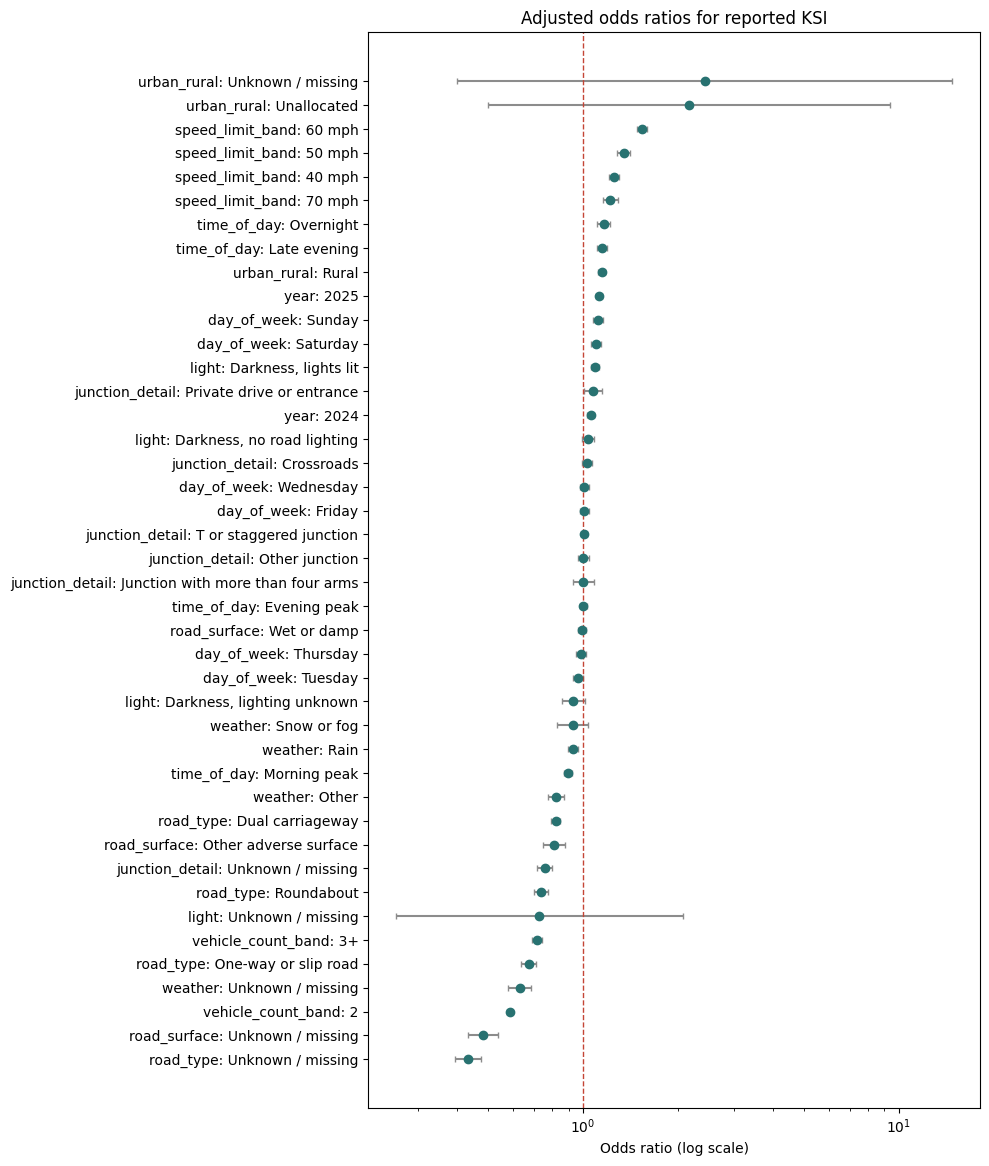

Saved forest plot to figures/logistic_forest_plot.png


In [3]:
_, design_matrix = dmatrices(formula, data=train, return_type="dataframe")
vif_rows = []
for position, column in enumerate(design_matrix.columns):
    if column == "Intercept":
        continue
    vif_rows.append(
        {
            "term": column,
            "vif": variance_inflation_factor(design_matrix.to_numpy(), position),
        }
    )
vif_table = pd.DataFrame(vif_rows).sort_values("vif", ascending=False)
print("Largest VIF values")
display(vif_table.head(12).round(2))

plot_data = odds_ratios.sort_values("odds_ratio").reset_index(drop=True)
plot_data["label"] = plot_data["term"].map(
    lambda term: f"{term[2:].split(',', 1)[0]}: {term.split('[T.', 1)[1][:-1]}"
    if term.startswith("C(") and "[T." in term
    else term
)
positions = np.arange(len(plot_data))
fig, axis = plt.subplots(figsize=(10, max(8, len(plot_data) * 0.28)))
axis.errorbar(
    plot_data["odds_ratio"],
    positions,
    xerr=[
        plot_data["odds_ratio"] - plot_data["ci_lower"],
        plot_data["ci_upper"] - plot_data["odds_ratio"],
    ],
    fmt="o",
    color="#287271",
    ecolor="#8c8c8c",
    capsize=2,
)
axis.axvline(1, color="#c44536", linestyle="--", linewidth=1)
axis.set_xscale("log")
axis.set_yticks(positions, plot_data["label"])
axis.set(title="Adjusted odds ratios for reported KSI", xlabel="Odds ratio (log scale)", ylabel="")
fig.tight_layout()
figure_path = PROJECT_ROOT / "figures" / "logistic_forest_plot.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved forest plot to {figure_path.relative_to(PROJECT_ROOT)}")

## Held-out check and interpretation

AUC measures how often the model ranks a randomly selected KSI collision above a slight collision. A constant-prevalence model has no ranking information and an AUC of 0.5. This check is secondary to interpreting adjusted associations.

In [4]:
test_predictions = model.predict(test)
test_auc = roc_auc_score(test["ksi"], test_predictions)
baseline_predictions = np.full(len(test), train["ksi"].mean())
baseline_auc = roc_auc_score(test["ksi"], baseline_predictions)

print(f"Test KSI rate: {test['ksi'].mean():.2%}")
print(f"Model test ROC AUC: {test_auc:.3f}")
print(f"Constant-prevalence baseline ROC AUC: {baseline_auc:.3f}")

speed_60 = odds_ratios[
    odds_ratios["term"].str.contains("speed_limit_band", regex=False)
    & odds_ratios["term"].str.contains("60 mph", regex=False)
]
if not speed_60.empty:
    estimate = speed_60.iloc[0]
    print(
        "\nInterpretation: compared with 20-30 mph, the estimated odds of a "
        f"reported KSI collision at 60 mph are {estimate['odds_ratio']:.2f} times "
        "as high, conditional on the other model variables. This is an association, "
        "not a causal effect."
    )

Test KSI rate: 25.00%
Model test ROC AUC: 0.621
Constant-prevalence baseline ROC AUC: 0.500

Interpretation: compared with 20-30 mph, the estimated odds of a reported KSI collision at 60 mph are 1.54 times as high, conditional on the other model variables. This is an association, not a causal effect.
